# 01 · Exploratory Data Analysis

**Goal:** EDA here is not "make some pretty plots". Every section answers a question whose answer
changes a modeling decision later. At the end we fill in a decisions table.

| # | Question | Decision it drives |
|---|---|---|
| Q1 | How big and how clean is the data? What *is* a track? | item ID definition, cleaning rules |
| Q2 | How active are users? | user filtering, who we can evaluate |
| Q3 | How long is the long tail? | item filtering, popularity baseline strength |
| Q4 | How much do people re-listen? | what we ask the model to predict |
| Q5 | How is data spread over time? | train/test cutoff date |
| Q6 | What do listening sessions look like? | input for the sequential (PyTorch) model |

After each section there is a **📝 Observation** cell. Write 1–2 sentences in your own words.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from musicrec import config
from musicrec.data import load_listens, load_users

pd.set_option("display.float_format", "{:,.3f}".format)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    """Save every figure so the README can use it later."""
    fig.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

df = load_listens()
users = load_users()
print(df.shape)
df.head()

(19150868, 6)


,user_id,ts,artist_mbid,artist_name,track_mbid,track_name
0,user_000001,2009-05-04 23:08:57+00:00,f1b1cf71-bd35-4e99-8624-24a6e15f133a,Deep Dish,NaN,Fuck Me Im Famous (Pacha Ibiza)-09-28-2007
1,user_000001,2009-05-04 13:54:10+00:00,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Composition 0919 (Live_2009_4_15)
2,user_000001,2009-05-04 13:52:04+00:00,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Mc2 (Live_2009_4_15)
3,user_000001,2009-05-04 13:42:52+00:00,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Hibari (Live_2009_4_15)
4,user_000001,2009-05-04 13:42:11+00:00,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Mc1 (Live_2009_4_15)


## Q1 · Size, quality, and "what is a track?"

`track_mbid` (MusicBrainz ID) would be a perfect track ID, but let's check how often it's missing. 
The missingness is totally fine!

In [3]:
pd.Series({
    "listens": len(df),
    "users": df["user_id"].nunique(),
    "distinct artist names": df["artist_name"].nunique(),
    "distinct track titles": df["track_name"].nunique(),
    "missing artist_mbid (%)": df["artist_mbid"].isna().mean() * 100,
    "missing track_mbid (%)": df["track_mbid"].isna().mean() * 100,
    "missing artist_name (rows)": df["artist_name"].isna().sum(),
    "missing track_name (rows)": df["track_name"].isna().sum(),
})

listens                      19,150,868.000
users                               992.000
distinct artist names           174,091.000
distinct track titles         1,084,873.000
missing artist_mbid (%)               3.144
missing track_mbid (%)               11.324
missing artist_name (rows)            0.000
missing track_name (rows)             0.000
dtype: float64

Can we use the **title alone** as the track ID? Count how many different artists share the same title: No we cannot use it alone as there are ~2200 share the same "intro" name.

In [4]:
# observed=True: only group by category values that actually occur.
# Without it, pandas builds a group for EVERY category (slow, and wrong counts).
title_artists = df.groupby("track_name", observed=True)["artist_name"].nunique()
title_artists.sort_values(ascending=False).head(8)

track_name
Intro           2193
Untitled         586
Outro            567
[Untitled]       499
Interlude        353
Home             296
Introduction     290
Bonus Track      266
Name: artist_name, dtype: int64

Titles collide ("Intro" belongs to thousands of artists), and MBIDs are often missing.
**Decision: a track = (artist_name, track_name).** `ngroup()` gives each distinct pair an integer ID.

In [5]:
before = len(df)
df = df.dropna(subset=["artist_name", "track_name"]).reset_index(drop=True)
print(f"dropped {before - len(df):,} rows with no artist or title")

df["track_key"] = df.groupby(["artist_name", "track_name"], observed=True, sort=False).ngroup().astype("int32")
print(f"distinct tracks (artist, title): {df['track_key'].nunique():,}")

dropped 0 rows with no artist or title
distinct tracks (artist, title): 1,500,661


Timestamps: Last.fm started in 2002, so anything earlier is a broken clock. And are there exact duplicate events? Only 2 exact duplicate events!

In [6]:
print("time range:", df["ts"].min(), "->", df["ts"].max())
print(df["ts"].dt.year.value_counts().sort_index())

dup = df.duplicated(subset=["user_id", "ts", "track_key"])
print(f"\nexact duplicate events (same user, same second, same track): {dup.sum():,} ({dup.mean():.2%})")

time range: 2005-02-14 00:00:07+00:00 -> 2013-09-29 18:32:04+00:00
ts
2005    1070656
2006    4255308
2007    5358216
2008    5929147
2009    2537539
2010          1
2013          1
Name: count, dtype: int64

exact duplicate events (same user, same second, same track): 2 (0.00%)


## Q2 · How active are users?

One row per user. `.agg` with named outputs keeps it readable: `new_column=(source_column, function)`.

In [7]:
per_user = df.groupby("user_id", observed=True).agg(
    listens=("ts", "size"),
    first=("ts", "min"),
    last=("ts", "max"),
    n_tracks=("track_key", "nunique"),
    n_artists=("artist_name", "nunique"),
)
per_user["span_days"] = (per_user["last"] - per_user["first"]).dt.days
per_user.describe(percentiles=[0.1, 0.5, 0.9]).T

,count,mean,std,min,10%,50%,90%,max
listens,992.000,"19,305.310","23,210.400",2.000,941.900,"11,551.000","47,159.300","183,103.000"
n_tracks,992.000,"4,655.535","5,381.189",2.000,496.100,"3,188.000","10,103.600","63,636.000"
n_artists,992.000,905.316,946.316,2.000,134.200,600.000,"2,067.800","8,398.000"
span_days,992.000,877.384,425.946,5.000,236.200,925.000,"1,442.900","2,291.000"


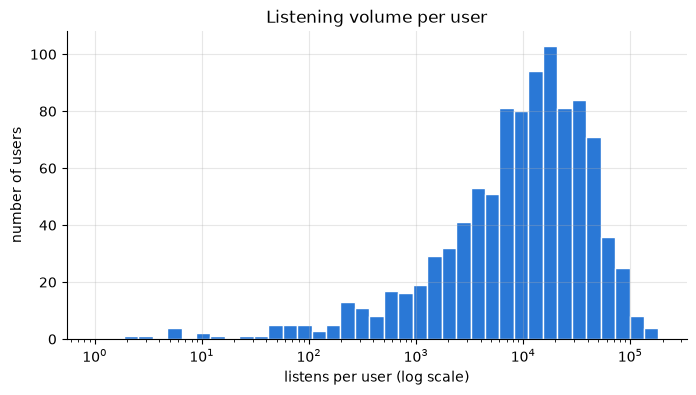

In [8]:
# Activity is heavy-tailed, so use log-spaced bins on a log axis
fig, ax = plt.subplots()
bins = np.logspace(0, np.log10(per_user["listens"].max()), 40)
ax.hist(per_user["listens"], bins=bins, color=BLUE, edgecolor="white")
ax.set_xscale("log")
ax.set(xlabel="listens per user (log scale)", ylabel="number of users", title="Listening volume per user")
save(fig, "01_listens_per_user")

## Q3 · The long tail

Collaborative filtering learns from *overlap between users*. A track heard by only one user
gives it nothing to learn from. How much of the catalog is like that?

In [9]:
track_plays = df["track_key"].value_counts()                      # sorted, most played first
artist_plays = df["artist_name"].value_counts().loc[lambda s: s > 0]
track_users = df.groupby("track_key")["user_id"].nunique()      # distinct listeners per track

def top_share(counts, frac):
    k = max(1, int(len(counts) * frac))
    return counts.iloc[:k].sum() / counts.sum()

for name, counts in [("tracks", track_plays), ("artists", artist_plays)]:
    print(f"{name:>8}: {len(counts):>9,} items | top 1% -> {top_share(counts, .01):.1%} of listens"
          f" | top 10% -> {top_share(counts, .10):.1%}")

for k in [1, 2, 5, 10]:
    print(f"tracks heard by <= {k:>2} users: {(track_users <= k).mean():.1%}")

  tracks: 1,500,661 items | top 1% -> 31.9% of listens | top 10% -> 71.2%
 artists:   174,091 items | top 1% -> 62.6% of listens | top 10% -> 91.9%
tracks heard by <=  1 users: 65.8%
tracks heard by <=  2 users: 79.1%
tracks heard by <=  5 users: 90.5%
tracks heard by <= 10 users: 95.2%


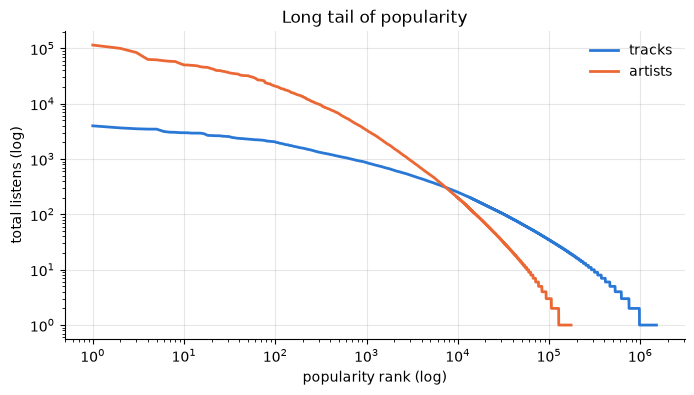

In [10]:
# Rank-frequency plot: a straight line on log-log axes = power law (classic long tail)
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(track_plays) + 1), track_plays.values, color=BLUE, lw=2, label="tracks")
ax.plot(np.arange(1, len(artist_plays) + 1), artist_plays.values, color=ORANGE, lw=2, label="artists")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set(xlabel="popularity rank (log)", ylabel="total listens (log)", title="Long tail of popularity")
ax.legend(frameon=False)
save(fig, "01_long_tail")

## Q4 · Repeat consumption (the most important question)

Music is unlike movies: people replay the same songs constantly. If most listens are repeats,
then "recommend what they already play" would score very well on a naive metric, but it isn't
a useful recommender. We need to know how big this effect is.

Trick: sort by user and time, then `duplicated(["user_id", "track_key"])` is `True` exactly when
this user has heard this track before.

In [11]:
df = df.sort_values(["user_id", "ts"], kind="stable").reset_index(drop=True)

df["is_repeat_track"] = df.duplicated(subset=["user_id", "track_key"])
df["is_repeat_artist"] = df.duplicated(subset=["user_id", "artist_name"])

print(f"listens that replay a track the user already heard:  {df['is_repeat_track'].mean():.1%}")
print(f"listens of an artist the user already heard:         {df['is_repeat_artist'].mean():.1%}")

listens that replay a track the user already heard:  75.9%
listens of an artist the user already heard:         95.3%


count   992.000
mean      0.614
std       0.250
min       0.000
25%       0.463
50%       0.678
75%       0.811
max       0.983
Name: is_repeat_track, dtype: float64

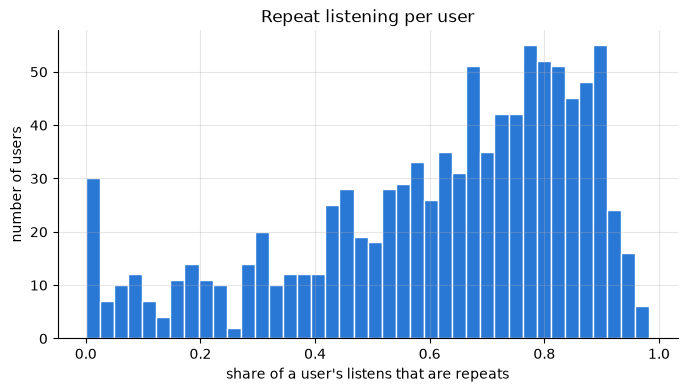

In [12]:
repeat_by_user = df.groupby("user_id", observed=True)["is_repeat_track"].mean()

fig, ax = plt.subplots()
ax.hist(repeat_by_user, bins=40, color=BLUE, edgecolor="white")
ax.set(xlabel="share of a user's listens that are repeats", ylabel="number of users",
       title="Repeat listening per user")
save(fig, "01_repeat_share")
repeat_by_user.describe()

## Q5 · Time coverage → where do we cut train/test?

We will train on the past and test on the future. For that we need to see how activity is
spread over time. Two measures with different scales get **two panels**, never two y-axes.

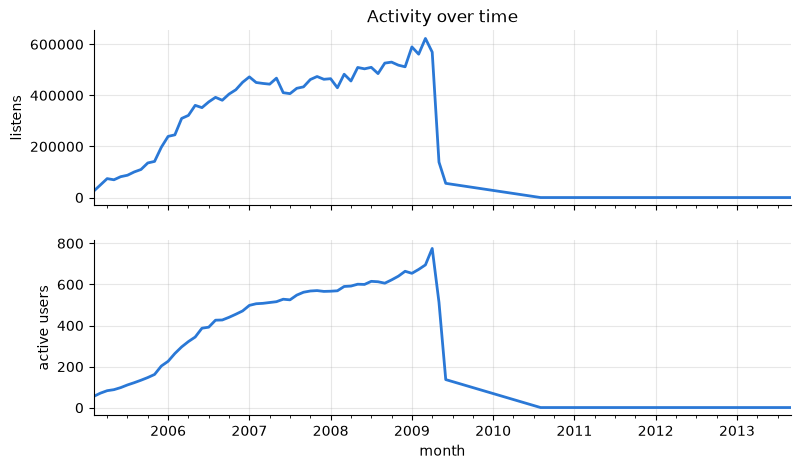

In [13]:
month = df["ts"].dt.tz_localize(None).dt.to_period("M")
monthly = df.groupby(month).agg(listens=("user_id", "size"), active_users=("user_id", "nunique"))
monthly = monthly.loc["2005-01":]

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
monthly["listens"].plot(ax=axes[0], color=BLUE, lw=2)
axes[0].set(ylabel="listens", title="Activity over time")
monthly["active_users"].plot(ax=axes[1], color=BLUE, lw=2)
axes[1].set(ylabel="active users", xlabel="month")
save(fig, "01_activity_over_time")

In [14]:
# For a few candidate cutoffs: how many users appear on BOTH sides (only they can be evaluated)?
rows = []
for cutoff in ["2008-11-01", "2009-01-01", "2009-03-01", "2009-04-01"]:
    c = pd.Timestamp(cutoff, tz="UTC")
    before = set(df.loc[df["ts"] < c, "user_id"].unique())
    after = set(df.loc[df["ts"] >= c, "user_id"].unique())
    rows.append({
        "cutoff": cutoff,
        "test listens": int((df["ts"] >= c).sum()),
        "test share": (df["ts"] >= c).mean(),
        "users on both sides": len(before & after),
    })
pd.DataFrame(rows)

,cutoff,test listens,test share,users on both sides
0,2008-11-01,3567713,0.186,875
1,2009-01-01,2537541,0.133,874
2,2009-03-01,1386472,0.072,893
3,2009-04-01,763601,0.040,875


## Q6 · Sessions

A session = consecutive listens with no gap longer than 30 minutes (a common convention).
Sessions will be the input sequences for the PyTorch model in stage 5.

In [15]:
gap_min = df["ts"].diff().dt.total_seconds() / 60
new_user = df["user_id"].ne(df["user_id"].shift())
gap_min = gap_min.where(~new_user)                 # gap across two users is meaningless

SESSION_GAP_MIN = 30
df["session_id"] = (new_user | (gap_min > SESSION_GAP_MIN)).cumsum()
session_len = df.groupby("session_id").size()

print(f"sessions: {len(session_len):,}")
session_len.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

sessions: 910,713


count   910,713.000
mean         21.028
std          49.213
min           1.000
25%           4.000
50%          10.000
75%          23.000
90%          47.000
99%         167.000
max       5,736.000
dtype: float64

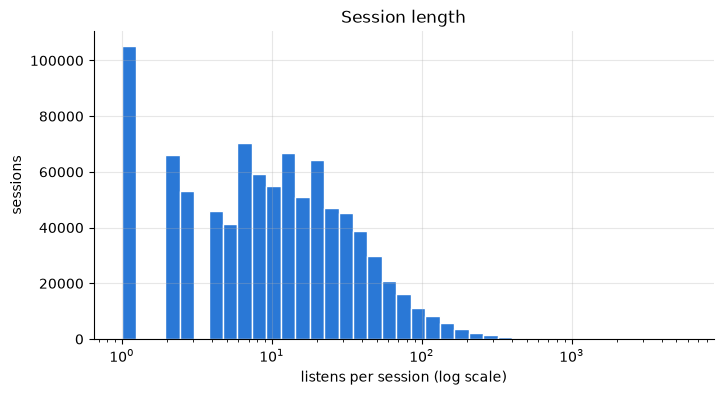

In [16]:
fig, ax = plt.subplots()
bins = np.logspace(0, np.log10(session_len.max()), 40)
ax.hist(session_len, bins=bins, color=BLUE, edgecolor="white")
ax.set_xscale("log")
ax.set(xlabel="listens per session (log scale)", ylabel="sessions", title="Session length")
save(fig, "01_session_length")

## Decisions (fill in together after running)

| Decision | Choice | Why (evidence from above) |
|---|---|---|
| Item ID | (artist_name, track_name) | |
| Duplicates | | |
| Minimum listeners per track | | |
| Repeats: predict all listens, or only new tracks? | | |
| Train/test cutoff | | |
| Session gap | 30 min | |